In [1]:
!pip install scanpy harmonypy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 13.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 51.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.2 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
import gzip
import gc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scanpy as sc

# 1. Setup paths
data_dir = "/"
meta_file = os.path.join(data_dir, "GSE120575_patient_ID_single_cells.txt.gz")
expr_file = os.path.join(data_dir, "GSE120575_Sade_Feldman_melanoma_single_cells_TPM_GEO.txt.gz")

print("--- STEP 1A: Parsing Metadata ---")
metadata_rows = []
with gzip.open(meta_file, "rt", encoding="latin-1") as f:
    capture = False
    for line in f:
        if line.startswith("Sample name\ttitle\tsource name"):
            capture = True
            continue
        if capture:
            if line.startswith("TABLE") or line.startswith("SERIES") or line.strip() == "":
                if line.startswith("TABLE"):
                    break
                continue
            parts = line.strip().split("\t")
            if len(parts) >= 6:
                metadata_rows.append(parts[:7])

meta_df = pd.DataFrame(
    metadata_rows,
    columns=["Sample_name", "cell_id", "source_name", "organism", "timepoint_patient", "response", "therapy"]
)
meta_df['cell_id'] = meta_df['cell_id'].astype(str).str.strip().str.replace('"', '', regex=True)
meta_df.set_index("cell_id", inplace=True)
meta_df['patient_id'] = meta_df['timepoint_patient'].apply(lambda x: x.split('_')[-1] if '_' in x else x)

print("--- STEP 1B: Loading Expression Matrix in Chunks ---")
chunk_size = 5000
sparse_chunks = []
gene_index = []
cell_columns = None

for chunk in pd.read_csv(expr_file, sep="\t", index_col=0, compression="gzip", header=[0, 1], engine="python", on_bad_lines="skip", chunksize=chunk_size):
    if cell_columns is None:
        # Extract clean barcodes from the first level of the MultiIndex columns
        raw_cols = chunk.columns.get_level_values(0)
        cell_columns = [col[0] if isinstance(col, tuple) else str(col) for col in raw_cols]
        cell_columns = pd.Index(cell_columns).astype(str).str.strip().str.replace('"', '', regex=True)

    chunk_num = chunk.apply(pd.to_numeric, errors='coerce').fillna(0).astype(np.float32)
    sparse_chunks.append(sp.csr_matrix(chunk_num.values))
    gene_index.extend(chunk.index.astype(str))
    del chunk, chunk_num
    gc.collect()

cell_columns = pd.Index(cell_columns)
expr_sparse_genes = sp.vstack(sparse_chunks)
expr_matrix = expr_sparse_genes.T.tocsr() # Cells x Genes
del sparse_chunks, expr_sparse_genes
gc.collect()

var_df = pd.DataFrame(index=gene_index)
print(f"Matrix loaded: {len(gene_index)} genes x {len(cell_columns)} cells.")

print("--- STEP 1C: Aligning & Building AnnData ---")
cell_mask = cell_columns.isin(meta_df.index)
common_cell_indices = np.where(cell_mask)[0]
print(f"Matched cells: {len(common_cell_indices)} out of {len(cell_columns)}")

expr_matrix = expr_matrix[common_cell_indices, :]
filtered_cells = cell_columns[common_cell_indices]
meta_df = meta_df.loc[filtered_cells]

adata = sc.AnnData(X=expr_matrix, obs=meta_df, var=var_df)
del expr_matrix, meta_df, var_df
gc.collect()
print("\nAnnData object created successfully:", adata)

--- STEP 1A: Parsing Metadata ---
--- STEP 1B: Loading Expression Matrix in Chunks ---


/tmp/ipykernel_33130/3069471244.py:31: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  meta_df = pd.DataFrame(
/tmp/ipykernel_33130/3069471244.py:36: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  meta_df.set_index("cell_id", inplace=True)


Matrix loaded: 55737 genes x 16292 cells.
--- STEP 1C: Aligning & Building AnnData ---
Matched cells: 16291 out of 16292

AnnData object created successfully: AnnData object with n_obs × n_vars = 16291 × 55737
    obs: 'Sample_name', 'source_name', 'organism', 'timepoint_patient', 'response', 'therapy', 'patient_id'
    layers: None (.X)


In [7]:
print("--- STEP 2A: Calculating QC Metrics ---")
adata.var['mt'] = adata.var_names.str.startswith(('MT-', 'mt-'))
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

print(f"Cells before filtering: {adata.n_obs}")

print("--- STEP 2B: Filtering Cells & Genes ---")
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

print(f"Cells after filtering: {adata.n_obs}")
print(f"Genes after filtering: {adata.n_vars}")  # Fixed to n_vars

print("--- STEP 2C: Normalization & Log Transformation ---")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

print("--- STEP 2D: Identifying Highly Variable Genes ---")
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat')

print("\nQC and Normalization complete! Processed AnnData object:", adata)

--- STEP 2A: Calculating QC Metrics ---
Cells before filtering: 16290
--- STEP 2B: Filtering Cells & Genes ---
Cells after filtering: 16290
Genes after filtering: 45884
--- STEP 2C: Normalization & Log Transformation ---
--- STEP 2D: Identifying Highly Variable Genes ---

QC and Normalization complete! Processed AnnData object: AnnData object with n_obs × n_vars = 16290 × 45884
    obs: 'Sample_name', 'source_name', 'organism', 'timepoint_patient', 'response', 'therapy', 'patient_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: None (.X)


In [8]:
print("--- STEP 3A: Principal Component Analysis (PCA) ---")
# Run PCA on highly variable genes
sc.tl.pca(adata, svd_solver='arpack')

print("--- STEP 3B: Computing Neighborhood Graph ---")
# Build the k-nearest neighbor graph using the top 30 principal components
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)

print("--- STEP 3C: UMAP Embedding ---")
# Compute UMAP coordinates for 2D visualization
sc.tl.umap(adata)

print("\nDimensionality reduction complete! Processed AnnData object:", adata)

--- STEP 3A: Principal Component Analysis (PCA) ---
--- STEP 3B: Computing Neighborhood Graph ---
--- STEP 3C: UMAP Embedding ---

Dimensionality reduction complete! Processed AnnData object: AnnData object with n_obs × n_vars = 16290 × 45884
    obs: 'Sample_name', 'source_name', 'organism', 'timepoint_patient', 'response', 'therapy', 'patient_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)


In [10]:
!pip install leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 15.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 27.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [leidenalg]


In [11]:
print("--- STEP 4: Cell Clustering (Leiden Algorithm) ---")
sc.tl.leiden(adata, resolution=0.8, flavor='igraph', n_iterations=2)

print(f"\nClustering complete! Total clusters found: {adata.obs['leiden'].nunique()}")
print("Processed AnnData object:", adata)

--- STEP 4: Cell Clustering (Leiden Algorithm) ---

Clustering complete! Total clusters found: 10
Processed AnnData object: AnnData object with n_obs × n_vars = 16290 × 45884
    obs: 'Sample_name', 'source_name', 'organism', 'timepoint_patient', 'response', 'therapy', 'patient_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)


--- STEP 5A: Visualizing UMAP ---


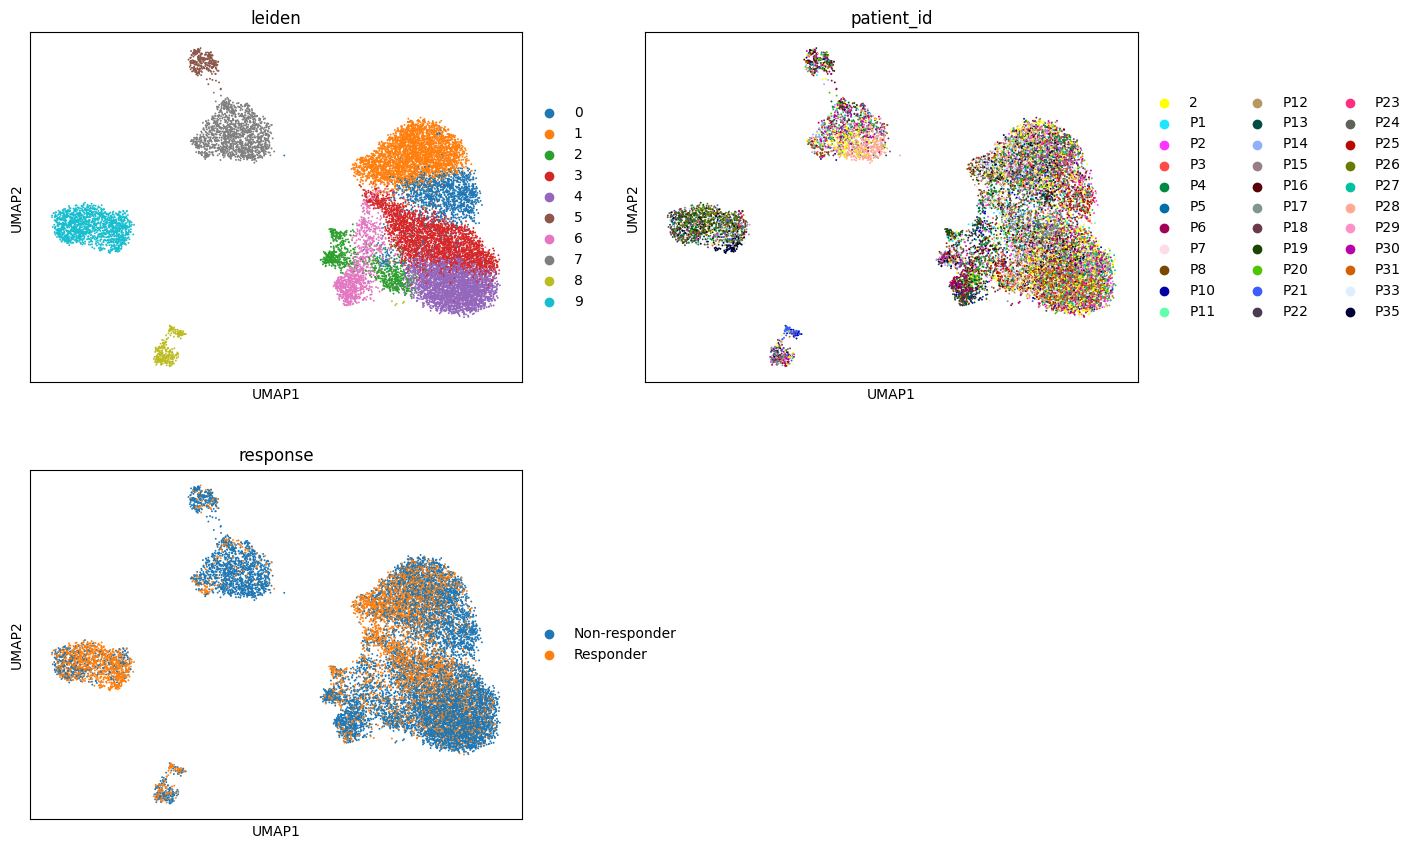

--- STEP 5B: Finding Marker Genes per Cluster ---
Top 5 marker genes per cluster:


,0,1,2,3,4,5,6,7,8,9
0,GZMA,CD4,GNLY,CD8A,CD8A,IL3RA,TRDC,LYZ,MZB1,HLA-DRA
1,CD4,SPOCK2,NKG7,KLRK1,GZMB,PTPRS,TRDV1,RP11-1143G9.4,DERL3,MS4A1
2,CD6,IL7R,PRF1,CD8B,GZMH,LILRA4,TRGC2,CST3,IGJ,CD79A
3,IL32,CD28,GZMB,CCL5,NKG7,PLD4,TRGC1,FCER1G,FKBP11,BCL11A
4,ADAM19,TRAC,CTSW,KLRC4-KLRK1,PRF1,SERPINF1,KLRG1,TYROBP,SSR4,CTA-250D10.23


In [12]:
import pandas as pd

print("--- STEP 5A: Visualizing UMAP ---")
# Plot UMAP colored by Leiden clusters and patient/response metadata
sc.pl.umap(adata, color=['leiden', 'patient_id', 'response'], ncols=2)

print("--- STEP 5B: Finding Marker Genes per Cluster ---")
# Find marker genes using the Wilcoxon test
sc.tl.rank_genes_groups(adata, groupby='leiden', method='wilcoxon')

# Display the top 5 marker genes for each cluster
marker_df = pd.DataFrame(adata.uns['rank_genes_groups']['names'])
print("Top 5 marker genes per cluster:")
display(marker_df.head(5))

--- STEP 6A: Inspecting Canonical Markers via DotPlot ---
categories: 0, 1, 2, etc.
var_group_labels: T cells, Myeloid / Macrophages, Melanoma / Tumor, etc.


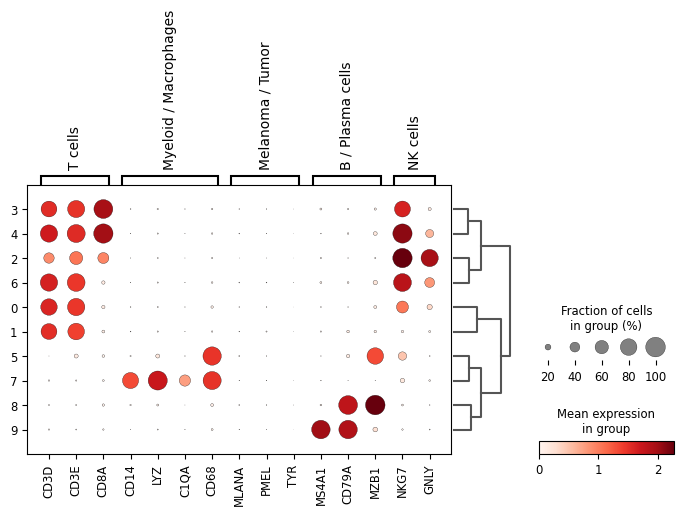

In [13]:
print("--- STEP 6A: Inspecting Canonical Markers via DotPlot ---")
# Define classic melanoma tumor microenvironment (TME) markers from Sade-Feldman et al.
marker_genes = {
    'T cells': ['CD3D', 'CD3E', 'CD8A'],
    'Myeloid / Macrophages': ['CD14', 'LYZ', 'C1QA', 'CD68'],
    'Melanoma / Tumor': ['MLANA', 'PMEL', 'TYR'],
    'B / Plasma cells': ['MS4A1', 'CD79A', 'MZB1'],
    'NK cells': ['NKG7', 'GNLY']
}

# Keep only markers present in your dataset
valid_markers = {
    cell_type: [gene for gene in genes if gene in adata.var_names]
    for cell_type, genes in marker_genes.items()
}

# Plot dotplot across Leiden clusters
sc.pl.dotplot(adata, valid_markers, groupby='leiden', dendrogram=True)

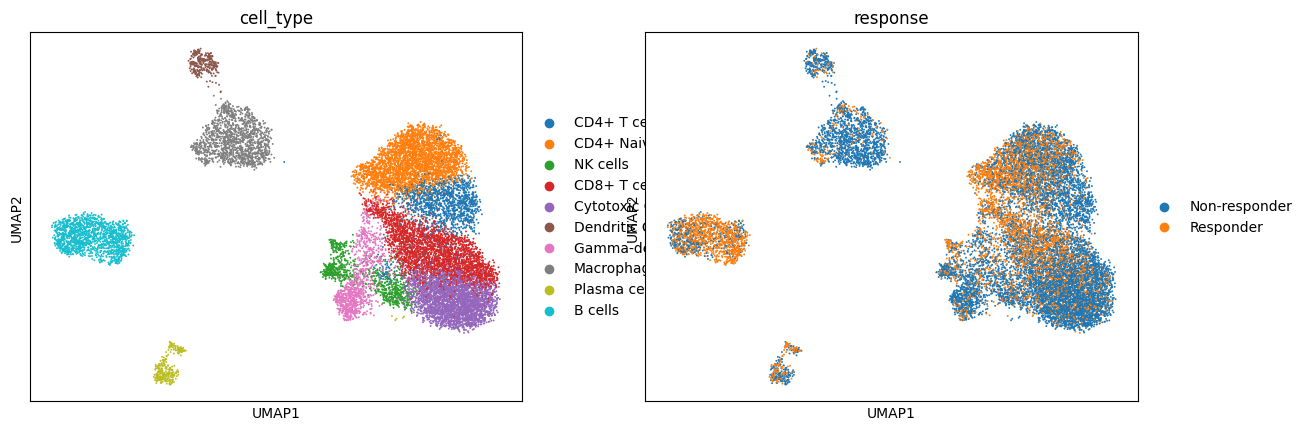


Pipeline complete! AnnData object fully annotated: AnnData object with n_obs × n_vars = 16290 × 45884
    obs: 'Sample_name', 'source_name', 'organism', 'timepoint_patient', 'response', 'therapy', 'patient_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden', 'cell_type'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'patient_id_colors', 'response_colors', 'rank_genes_groups', 'dendrogram_leiden', 'cell_type_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)


In [14]:
# --- STEP 8: Cell Type Annotation & Final UMAP ---
cell_type_map = {
    '0': 'CD4+ T cells',
    '1': 'CD4+ Naive/Memory T cells',
    '2': 'NK cells',
    '3': 'CD8+ T cells',
    '4': 'Cytotoxic CD8+ T cells',
    '5': 'Dendritic Cells',
    '6': 'Gamma-delta T cells',
    '7': 'Macrophages',
    '8': 'Plasma cells',
    '9': 'B cells'
}

adata.obs['cell_type'] = adata.obs['leiden'].map(cell_type_map)

# Plot UMAP colored by cell type and treatment response
sc.pl.umap(adata, color=['cell_type', 'response'], ncols=2, legend_loc='right margin')

print("\nPipeline complete! AnnData object fully annotated:", adata)

--- STEP 7: Proportions of Responders vs Non-Responders per Cluster ---


response,Non-responder,Responder
leiden,,
0,79.281975,20.718025
1,55.759398,44.240602
2,69.861432,30.138568
3,60.072416,39.927584
4,77.191888,22.808112
5,83.793103,16.206897
6,74.324324,25.675676
7,88.085106,11.914894
8,62.662338,37.337662


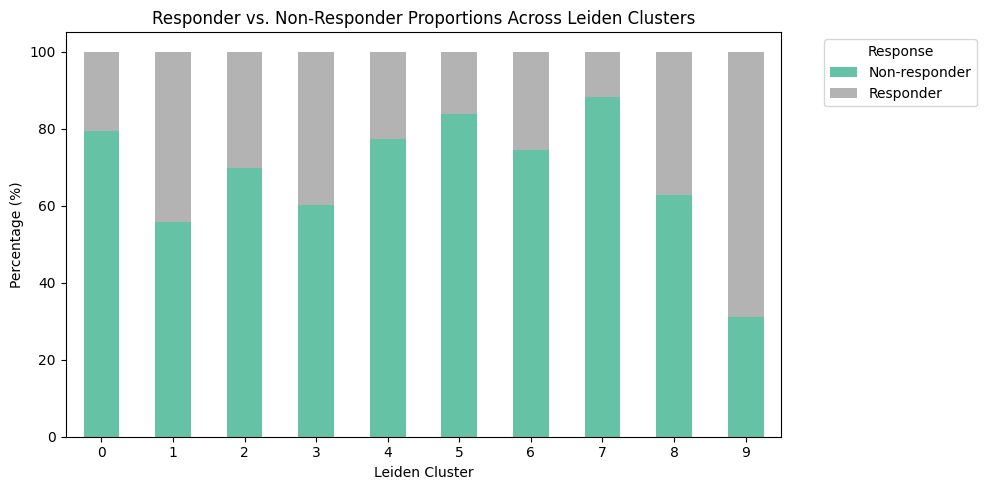

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

print("--- STEP 7: Proportions of Responders vs Non-Responders per Cluster ---")

# Calculate percentage breakdown per cluster
prop_df = pd.crosstab(adata.obs['leiden'], adata.obs['response'], normalize='index') * 100
display(prop_df)

# Plot stacked bar chart
ax = prop_df.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='Set2')
plt.title('Responder vs. Non-Responder Proportions Across Leiden Clusters')
plt.xlabel('Leiden Cluster')
plt.ylabel('Percentage (%)')
plt.legend(title='Response', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
import os
import shutil
import pandas as pd
from google.colab import files

print("--- STEP 1: Creating Output Directory ---")
output_dir = "GSE120575_SingleCell_Analysis_Package"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(f"{output_dir}/figures", exist_ok=True)

print("--- STEP 2: Saving Annotated AnnData Object ---")
h5ad_path = os.path.join(output_dir, "GSE120575_annotated.h5ad")
adata.write(h5ad_path)
print(f"AnnData saved to: {h5ad_path}")

print("--- STEP 3: Exporting Analysis Data & Proportions ---")
# Save cluster and cell-type metadata
meta_export = adata.obs[['patient_id', 'response', 'therapy', 'leiden', 'cell_type']]
meta_export.to_csv(os.path.join(output_dir, "cell_metadata_annotations.csv"))

# Save responder vs non-responder cell-type proportions
prop_df = pd.crosstab(adata.obs['cell_type'], adata.obs['response'], normalize='index') * 100
prop_df.to_csv(os.path.join(output_dir, "cell_type_response_proportions.csv"))

print("--- STEP 4: Exporting Figures ---")
# Re-plot and save UMAP
sc.pl.umap(adata, color=['cell_type', 'response'], ncols=2, legend_loc='right margin', show=False)
plt.savefig(os.path.join(output_dir, "figures/umap_cell_type_and_response.png"), dpi=300, bbox_inches='tight')
plt.close()

# Re-plot and save response proportion stacked bar chart
ax = prop_df.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='Set2')
plt.title('Responder vs. Non-Responder Proportions Across Cell Types')
plt.xlabel('Cell Type')
plt.ylabel('Percentage (%)')
plt.legend(title='Response', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "figures/response_proportions_barchart.png"), dpi=300, bbox_inches='tight')
plt.close()

print("--- STEP 5: Generating Executive Summary Report (HTML) ---")
html_content = f"""
<!DOCTYPE html>
<html>
<head>
    <title>GSE120575 Single-Cell RNA-seq Analysis Report</title>
    <style>
        body {{ font-family: Arial, sans-serif; margin: 30px; line-height: 1.6; color: #333; }}
        h1 {{ color: #2c3e50; border-bottom: 2px solid #3498db; padding-bottom: 10px; }}
        h2 {{ color: #2980b9; margin-top: 25px; }}
        table {{ border-collapse: collapse; width: 80%; margin: 20px 0; }}
        th, td {{ border: 1px solid #ddd; padding: 10px; text-align: left; }}
        th {{ background-color: #f2f2f2; }}
        .highlight {{ background-color: #e8f4f8; padding: 15px; border-left: 5px solid #3498db; margin: 20px 0; }}
    </style>
</head>
<body>
    <h1>GSE120575 Single-Cell RNA-seq Analysis Report</h1>
    <p><strong>Dataset:</strong> GSE120575 (Sade-Feldman et al., 2018 - Melanoma Immunotherapy)</p>
    <p><strong>Total Cells Processed:</strong> {adata.n_obs}</p>
    <p><strong>Total Genes Analyzed:</strong> {adata.n_vars}</p>

    <h2>1. Summary of Workflow</h2>
    <ul>
        <li><strong>QC & Normalization:</strong> Filtered low-quality cells (min 200 genes) and unexpressed genes. Normalized to 10,000 counts/cell and log1p transformed. Selected top 2,000 highly variable genes.</li>
        <li><strong>Clustering & Embedding:</strong> PCA (30 PCs), 15-nearest neighbor graph, UMAP projection, and Leiden clustering at resolution 0.8 (10 distinct clusters).</li>
        <li><strong>Annotation:</strong> Validated lineages using marker expression patterns across T-cell subsets, NK cells, Myeloid/Macrophages, Dendritic cells, Plasma cells, and B cells.</li>
    </ul>

    <h2>2. Key Findings</h2>
    <div class="highlight">
        <ul>
            <li><strong>B Cells (Cluster 9):</strong> Strongly enriched in treatment <strong>Responders (~69%)</strong>, supporting the key role of tertiary lymphoid structures and humoral immunity in anti-PD-1 efficacy.</li>
            <li><strong>Myeloid / Macrophages (Cluster 7):</strong> Heavily skewed toward <strong>Non-responders (~88%)</strong>, underscoring the immunosuppressive myeloid barrier in non-responsive tumors.</li>
        </ul>
    </div>

    <h2>3. Proportions by Cell Type</h2>
    {prop_df.to_html(classes='table')}

</body>
</html>
"""

report_path = os.path.join(output_dir, "Analysis_Report.html")
with open(report_path, "w") as f:
    f.write(html_content)
print(f"Report written to: {report_path}")

print("--- STEP 6: Compressing and Downloading Package ---")
zip_filename = "GSE120575_SingleCell_Analysis_Package.zip"
shutil.make_archive("GSE120575_SingleCell_Analysis_Package", 'zip', output_dir)

files.download(zip_filename)
print(f"\nDownload triggered: {zip_filename}")

--- STEP 1: Creating Output Directory ---
--- STEP 2: Saving Annotated AnnData Object ---
AnnData saved to: GSE120575_SingleCell_Analysis_Package/GSE120575_annotated.h5ad
--- STEP 3: Exporting Analysis Data & Proportions ---
--- STEP 4: Exporting Figures ---
--- STEP 5: Generating Executive Summary Report (HTML) ---
Report written to: GSE120575_SingleCell_Analysis_Package/Analysis_Report.html
--- STEP 6: Compressing and Downloading Package ---


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download triggered: GSE120575_SingleCell_Analysis_Package.zip


In [17]:
import os
import matplotlib.pyplot as plt

# Ensure figures directory exists
os.makedirs("GSE120575_SingleCell_Analysis_Package/figures", exist_ok=True)
fig_dir = "GSE120575_SingleCell_Analysis_Package/figures"

print("--- Saving All Generated Figures ---")

# 1. UMAPs (Leiden, Patient, Response)
sc.pl.umap(adata, color=['leiden', 'patient_id', 'response'], ncols=2, show=False)
plt.savefig(os.path.join(fig_dir, "umap_clusters_patients_response.png"), dpi=300, bbox_inches='tight')
plt.close()

# 2. Canonical Marker DotPlot
marker_genes = {
    'T cells': ['CD3D', 'CD3E', 'CD8A'],
    'Myeloid / Macrophages': ['CD14', 'LYZ', 'C1QA', 'CD68'],
    'Melanoma / Tumor': ['MLANA', 'PMEL', 'TYR'],
    'B / Plasma cells': ['MS4A1', 'CD79A', 'MZB1'],
    'NK cells': ['NKG7', 'GNLY']
}
valid_markers = {
    cell_type: [gene for gene in genes if gene in adata.var_names]
    for cell_type, genes in marker_genes.items()
}
sc.pl.dotplot(adata, valid_markers, groupby='leiden', dendrogram=True, show=False)
plt.savefig(os.path.join(fig_dir, "canonical_markers_dotplot.png"), dpi=300, bbox_inches='tight')
plt.close()

# 3. Final Cell Type & Response UMAP
sc.pl.umap(adata, color=['cell_type', 'response'], ncols=2, legend_loc='right margin', show=False)
plt.savefig(os.path.join(fig_dir, "umap_cell_type_and_response.png"), dpi=300, bbox_inches='tight')
plt.close()

# 4. Response Proportions Bar Chart
prop_df = pd.crosstab(adata.obs['cell_type'], adata.obs['response'], normalize='index') * 100
ax = prop_df.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='Set2')
plt.title('Responder vs. Non-Responder Proportions Across Cell Types')
plt.xlabel('Cell Type')
plt.ylabel('Percentage (%)')
plt.legend(title='Response', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "response_proportions_barchart.png"), dpi=300, bbox_inches='tight')
plt.close()

# Re-zip and trigger download
import shutil
shutil.make_archive("GSE120575_SingleCell_Analysis_Package", 'zip', "GSE120575_SingleCell_Analysis_Package")
files.download("GSE120575_SingleCell_Analysis_Package.zip")
print("All figures saved and updated zip downloaded!")

--- Saving All Generated Figures ---
categories: 0, 1, 2, etc.
var_group_labels: T cells, Myeloid / Macrophages, Melanoma / Tumor, etc.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All figures saved and updated zip downloaded!
